# Building a Diffusion Model from Scratch (CPU Only)

Welcome! In this notebook, we will build a **Denoising Diffusion Probabilistic Model (DDPM)** from scratch using PyTorch.

### What is a Diffusion Model?
Diffusion models work in two phases:
1. **Forward Process (Diffusion):** We slowly add Gaussian noise to an image over $T$ steps until it becomes pure static.
2. **Reverse Process (Denoising):** We train a neural network to predict and remove that noise step-by-step, learning how to generate images from pure static.

### CPU Constraints
Training diffusion models usually requires massive GPUs. To make this run on a CPU in a reasonable time, we will:
- Use the **MNIST dataset** (small 28x28 grayscale images).
- Reduce the number of diffusion steps ($T$) from the standard 1000 down to **100**.
- Use a highly stripped-down, lightweight U-Net architecture without attention mechanisms.

Let's begin by importing our libraries!

In [1]:
# Import necessary PyTorch and utility libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader


# For reproducibility
torch.manual_seed(42)

## 1. The Diffusion Scheduler

Before building the neural network, we need to define the mathematical rules for adding and removing noise. This is handled by the `DiffusionScheduler`.

### The Forward Process Math
To add noise to an original image $x_0$ at timestep $t$, we use this formula:
$$x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \epsilon$$
Where:
- $\epsilon$ is random Gaussian noise.
- $\bar{\alpha}_t$ is a precomputed value that dictates how much "signal" (original image) vs "noise" is present at step $t$. As $t$ approaches $T$, $\bar{\alpha}_t$ approaches 0, meaning the image becomes pure noise.

We will precompute these values so we don't have to calculate them on the fly during training.

In [2]:
class DiffusionScheduler:
    def __init__(self, num_timesteps=100, beta_start=1e-4, beta_end=0.02):
        self.num_timesteps = num_timesteps

        # Linear beta schedule: controls the variance of the noise added at each step
        self.betas = torch.linspace(beta_start, beta_end, num_timesteps)

        # Precompute alphas (1 - beta) and their cumulative products (alpha_bar)
        self.alphas = 1.0 - self.betas
        self.alphas_bar = torch.cumprod(self.alphas, dim=0)

        # Precompute square roots for the forward and reverse processes
        self.sqrt_alphas_bar = torch.sqrt(self.alphas_bar)
        self.sqrt_one_minus_alphas_bar = torch.sqrt(1.0 - self.alphas_bar)
        self.sqrt_recip_alphas = torch.sqrt(1.0 / self.alphas)

    def get_noisy(self, x_0, t, noise):
        """Forward process: Add noise to x_0 at timestep t"""
        # Reshape tensors for broadcasting: (Batch) -> (Batch, 1, 1, 1)
        sqrt_alpha_bar = self.sqrt_alphas_bar[t][:, None, None, None]
        sqrt_one_minus_alpha_bar = self.sqrt_one_minus_alphas_bar[t][:, None, None, None]

        # Apply the forward diffusion formula
        return sqrt_alpha_bar * x_0 + sqrt_one_minus_alpha_bar * noise

    def p_sample(self, model, x_t, t):
        """Reverse process: Denoise x_t to x_{t-1} using the trained model"""
        with torch.no_grad():
            # 1. Ask the model to predict the noise in the current image
            predicted_noise = model(x_t, t)

            # 2. Calculate the mean of the reverse step distribution
            alpha = self.alphas[t][:, None, None, None]
            sqrt_recip_alpha = self.sqrt_recip_alphas[t][:, None, None, None]
            sqrt_one_minus_alpha_bar = self.sqrt_one_minus_alphas_bar[t][:, None, None, None]

            mean = sqrt_recip_alpha * (x_t - (1 - alpha) / sqrt_one_minus_alpha_bar * predicted_noise)

            # 3. If we aren't at the final step (t=0), add a little random noise
            if t[0] > 0:
                beta = self.betas[t][:, None, None, None]
                noise = torch.randn_like(x_t)
                return mean + torch.sqrt(beta) * noise
            else:
                return mean

## 2. The Denoising Network (Lightweight U-Net)

The core of a diffusion model is a neural network that takes a noisy image and a timestep $t$, and predicts the noise $\epsilon$ that was added.

### Why a Lightweight U-Net?m
Standard diffusion models use massive U-Nets with self-attention. Self-attention scales quadratically with image size, which would freeze a CPU. Our version uses standard convolutions and downsampling/upsampling.

### Time Embeddings
The network needs to know *how much* noise is in the image (the timestep $t$). We convert the scalar timestep into a vector using **Sinusoidal Positional Embeddings** (the same math used in Transformers for word positions). We then inject this vector into the network via addition at various layers.

In [3]:
class SinusoidalPositionEmbedding(nn.Module):
    """Converts a scalar timestep into a rich vector representation."""
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        device = t.device
        half_dim = self.dim // 2
        emb = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device) * -emb)
        emb = t[:, None] * emb[None, :]
        return torch.cat([torch.sin(emb), torch.cos(emb)], dim=-1)

class LightweightUNet(nn.Module):
    def __init__(self, time_dim=32, channels=32):
        super().__init__()

        # 1. Time Embedding MLP
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbedding(time_dim),
            nn.Linear(time_dim, time_dim * 4),
            nn.GELU(),
        )

        # Linear layers to project time embeddings to match our convolution channels
        self.time_proj1 = nn.Linear(time_dim * 4, channels)
        self.time_proj2 = nn.Linear(time_dim * 4, channels * 2)
        self.time_proj3 = nn.Linear(time_dim * 4, channels * 2)
        self.time_proj4 = nn.Linear(time_dim * 4, channels)

        # 2. Encoder (Downsampling path)
        # Input: 1 channel (grayscale), Output: 32 channels, Size: 28x28
        self.conv1 = nn.Conv2d(1, channels, 3, padding=1)
        # Stride 2 halves the spatial dimensions: 28x28 -> 14x14
        self.conv2 = nn.Conv2d(channels, channels * 2, 3, stride=2, padding=1)

        # 3. Bottleneck
        self.conv3 = nn.Conv2d(channels * 2, channels * 2, 3, padding=1)

        # 4. Decoder (Upsampling path)
        # Transposed convolution doubles the spatial dimensions: 14x14 -> 28x28
        self.conv4 = nn.ConvTranspose2d(channels * 2, channels, 4, stride=2, padding=1)
        # Final layer maps back to 1 channel (the predicted noise image)
        self.conv5 = nn.Conv2d(channels, 1, 3, padding=1)

    def forward(self, x, t):
        # Process the timestep into a vector
        t_emb = self.time_mlp(t)

        # --- ENCODER ---
        h1 = self.conv1(x)
        # Inject time information by adding the projected time embedding
        h1 = h1 + self.time_proj1(t_emb)[:, :, None, None]
        h1 = F.silu(h1) # SiLU (Swish) activation

        h2 = self.conv2(h1)
        h2 = h2 + self.time_proj2(t_emb)[:, :, None, None]
        h2 = F.silu(h2)

        # --- BOTTLENECK ---
        h3 = self.conv3(h2)
        h3 = h3 + self.time_proj3(t_emb)[:, :, None, None]
        h3 = F.silu(h3)

        # --- DECODER ---
        h4 = self.conv4(h3)
        h4 = h4 + self.time_proj4(t_emb)[:, :, None, None]
        h4 = F.silu(h4)

        out = self.conv5(h4)
        return out

## 3. The Training Loop

Now we train the model. The training objective is simple:
1. Take a clean image $x_0$.
2. Pick a random timestep $t$ and generate random noise $\epsilon$.
3. Use our scheduler to create a noisy image $x_t$.
4. Pass $x_t$ and $t$ into our U-Net to predict the noise $\hat{\epsilon}$.
5. Calculate the **Mean Squared Error (MSE)** between the actual noise $\epsilon$ and predicted noise $\hat{\epsilon}$.
6. Backpropagate and update weights.

*Note: We scale the MNIST images from `[0, 1]` to `[-1, 1]`. This is crucial because Gaussian noise is centered at 0, so our data must be too!*

In [4]:
device = torch.device("cpu")

In [5]:
def train_cpu_diffusion(epochs=2, batch_size=128, lr=2e-4):
    # 1. Setup Data
    # Lambda scales pixels from [0, 1] to [-1, 1]
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Lambda(lambda t: (t * 2) - 1)
    ])
    dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
    # num_workers=0 prevents multiprocessing issues on some CPU/OS setups
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0)

    # 2. Setup Model, Scheduler, Optimizer
    model = LightweightUNet(time_dim=32, channels=32).to(device)
    scheduler = DiffusionScheduler(num_timesteps=100)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    # Move scheduler tensors to the correct device
    for attr in dir(scheduler):
        val = getattr(scheduler, attr)
        if isinstance(val, torch.Tensor):
            setattr(scheduler, attr, val.to(device))

    print(f"Starting training on {device}...")
    model.train()

    for epoch in range(epochs):
        epoch_loss = 0
        for step, (batch, _) in enumerate(dataloader):
            batch = batch.to(device)
            B = batch.shape[0]

            # Sample random timesteps for each image in the batch
            t = torch.randint(0, scheduler.num_timesteps, (B,), device=device).long()
            # Sample random noise
            noise = torch.randn_like(batch).to(device)

            # Create noisy images
            x_t = scheduler.get_noisy(batch, t, noise)

            # Predict noise and calculate loss
            predicted_noise = model(x_t, t)
            loss = F.mse_loss(predicted_noise, noise)

            # Backpropagation
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

            if step % 100 == 0:
                print(f"Epoch {epoch+1}/{epochs} | Step {step} | Loss: {loss.item():.4f}")

        print(f"--> Epoch {epoch+1} finished. Avg Loss: {epoch_loss/len(dataloader):.4f}\n")

    return model, scheduler

# --- Run Training ---
# Note: On a CPU, 2 epochs will take roughly 3-5 minutes.
# You will start seeing faint digit shapes after just 2 epochs!
trained_model, diffusion_scheduler = train_cpu_diffusion(epochs=2, batch_size=128)

100%|██████████| 9.91M/9.91M [00:00<00:00, 133MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 34.8MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 138MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.09MB/s]


Starting training on cpu...
Epoch 1/2 | Step 0 | Loss: 1.0045
Epoch 1/2 | Step 100 | Loss: 0.4486
Epoch 1/2 | Step 200 | Loss: 0.3585
Epoch 1/2 | Step 300 | Loss: 0.2719
Epoch 1/2 | Step 400 | Loss: 0.2657
--> Epoch 1 finished. Avg Loss: 0.4023

Epoch 2/2 | Step 0 | Loss: 0.2661
Epoch 2/2 | Step 100 | Loss: 0.2284
Epoch 2/2 | Step 200 | Loss: 0.2055
Epoch 2/2 | Step 300 | Loss: 0.1991
Epoch 2/2 | Step 400 | Loss: 0.2235
--> Epoch 2 finished. Avg Loss: 0.2103



## 4. Sampling (Generating Images)

Training is done! Now we use the **Reverse Process** to generate new images.

We start with a tensor of pure, random Gaussian noise (shape: `[batch, 1, 28, 28]`).
We then loop backwards from $T=99$ down to $0$. At each step, we ask our trained U-Net to predict the noise, subtract it, and pass the slightly cleaner image to the next step.

By the time we reach $t=0$, the pure noise has been sculpted into a recognizable MNIST digit!

Generating 8 images... (This takes a few seconds on CPU)


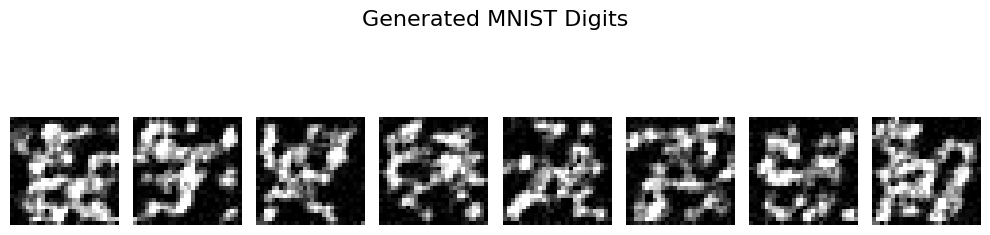

In [6]:
def generate_images(model, scheduler, num_images=4):
    device = next(model.parameters()).device
    model.eval() # Set to evaluation mode (disables dropout, etc.)

    print(f"Generating {num_images} images... (This takes a few seconds on CPU)")

    # Start with pure random noise
    x = torch.randn((num_images, 1, 28, 28), device=device)

    # Iterative denoising loop (backwards from T-1 to 0)
    for i in range(0, scheduler.num_timesteps)[::-1]:
        t = torch.full((num_images,), i, device=device, dtype=torch.long)
        x = scheduler.p_sample(model, x, t)

    # Scale images back from [-1, 1] to [0, 1] for matplotlib
    x = (x + 1) * 0.5
    # Clamp to ensure no pixel values fall outside valid image ranges
    x = torch.clamp(x, 0.0, 1.0)

    # Plot the generated images
    fig, axes = plt.subplots(1, num_images, figsize=(10, 3))
    fig.suptitle('Generated MNIST Digits', fontsize=16)
    for i in range(num_images):
        axes[i].imshow(x[i].squeeze().cpu().numpy(), cmap='gray')
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

# --- Generate and Display ---
generate_images(trained_model, diffusion_scheduler, num_images=8)